L2 REGULARIZATION

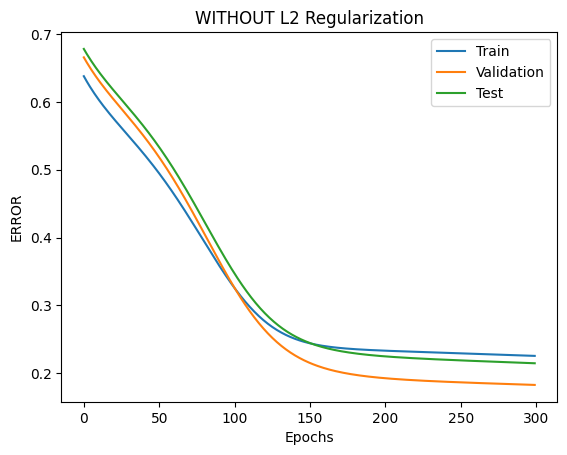

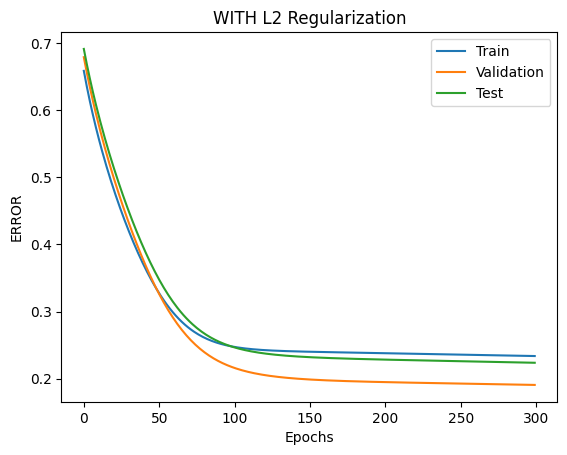

TEST COMPARISON
No L2  -> MSE: 0.2148780340975998 Accuracy: 0.93
With L2-> MSE: 0.22383840682849843 Accuracy: 0.93


In [41]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)


N = 1000
X = np.random.uniform(-3, 3, (N, 1))
y = np.sin(X) + 0.3 * np.random.randn(N, 1)


train_X, val_X, test_X = X[:600], X[600:800], X[800:]
train_y, val_y, test_y = y[:600], y[600:800], y[800:]


class MLP:
    def __init__(self, l2=0.0):
        self.W1 = np.random.randn(1, 32) * 0.1
        self.b1 = np.zeros((1, 32))
        self.W2 = np.random.randn(32, 16) * 0.1
        self.b2 = np.zeros((1, 16))
        self.W3 = np.random.randn(16, 1) * 0.1
        self.b3 = np.zeros((1, 1))
        self.l2 = l2

    def forward(self, X):
        self.z1 = X @ self.W1 + self.b1
        self.a1 = np.tanh(self.z1)
        self.z2 = self.a1 @ self.W2 + self.b2
        self.a2 = np.tanh(self.z2)
        self.out = self.a2 @ self.W3 + self.b3
        return self.out

    def mse(self, y, yhat):
        return np.mean((y - yhat) ** 2)

    def backward(self, X, y, lr):
        m = len(y)
        d_out = 2 * (self.out - y) / m

        dW3 = self.a2.T @ d_out + self.l2 * self.W3
        db3 = np.sum(d_out, axis=0, keepdims=True)

        da2 = d_out @ self.W3.T
        dz2 = da2 * (1 - np.tanh(self.z2)**2)

        dW2 = self.a1.T @ dz2 + self.l2 * self.W2
        db2 = np.sum(dz2, axis=0, keepdims=True)

        da1 = dz2 @ self.W2.T
        dz1 = da1 * (1 - np.tanh(self.z1)**2)

        dW1 = X.T @ dz1 + self.l2 * self.W1
        db1 = np.sum(dz1, axis=0, keepdims=True)

        self.W3 -= lr * dW3
        self.b3 -= lr * db3
        self.W2 -= lr * dW2
        self.b2 -= lr * db2
        self.W1 -= lr * dW1
        self.b1 -= lr * db1



W1_history = []


  

def train_model(l2):
    model = MLP(l2=l2)
    lr = 0.01
    epochs = 300

    train_err, val_err, test_err = [], [], []

    for _ in range(epochs):
        yhat = model.forward(train_X)
        model.backward(train_X, train_y, lr)
        W1_history.append(model.W1.flatten())

        train_err.append(model.mse(train_y, yhat))
        val_err.append(model.mse(val_y, model.forward(val_X)))
        test_err.append(model.mse(test_y, model.forward(test_X)))

    return model, train_err, val_err, test_err


model_no_l2, tr_nl, val_nl, te_nl = train_model(l2=0.0)
model_l2, tr_l2, val_l2, te_l2 = train_model(l2=0.01)


plt.figure()
plt.plot(tr_nl, label="Train")
plt.plot(val_nl, label="Validation")
plt.plot(te_nl, label="Test")
plt.title("WITHOUT L2 Regularization")
plt.xlabel("Epochs")
plt.ylabel("ERROR")
plt.legend()
plt.show()

plt.figure()
plt.plot(tr_l2, label="Train")
plt.plot(val_l2, label="Validation")
plt.plot(te_l2, label="Test")
plt.title("WITH L2 Regularization")
plt.xlabel("Epochs")
plt.ylabel("ERROR")
plt.legend()
plt.show()


def accuracy(y, yhat):
    return np.mean((yhat > 0) == (y > 0))

pred_nl = model_no_l2.forward(test_X)
pred_l2 = model_l2.forward(test_X)

print("TEST COMPARISON")
print("No L2  -> MSE:", model_no_l2.mse(test_y, pred_nl),
      "Accuracy:", accuracy(test_y, pred_nl))

print("With L2-> MSE:", model_l2.mse(test_y, pred_l2),
      "Accuracy:", accuracy(test_y, pred_l2))


2 . DATA AUGMENTATION , EARLY STOPPING , DROP OUT

In [10]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
import numpy as np


In [11]:
class SimpleMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28*28, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.net(x)


In [12]:
def get_20_per_class(dataset):
    targets = np.array(dataset.targets)
    indices = []

    for cls in range(10):
        cls_idx = np.where(targets == cls)[0][:100]
        indices.extend(cls_idx)

    return Subset(dataset, indices)


In [13]:
transform_no_aug = transforms.Compose([
    transforms.ToTensor()
])


In [14]:
transform_aug = transforms.Compose([
    transforms.RandomRotation(15),
    transforms.RandomAffine(0, translate=(0.1, 0.1)),
    transforms.ToTensor()
])


In [15]:
train_no_aug = datasets.MNIST(
    root="./data", train=True, download=True,
    transform=transform_no_aug
)

train_aug = datasets.MNIST(
    root="./data", train=True, download=True,
    transform=transform_aug
)

test_set = datasets.MNIST(
    root="./data", train=False, download=True,
    transform=transform_no_aug
)

train_no_aug = get_20_per_class(train_no_aug)
train_aug = get_20_per_class(train_aug)

train_loader_no_aug = DataLoader(train_no_aug, batch_size=32, shuffle=True)
train_loader_aug = DataLoader(train_aug, batch_size=32, shuffle=True)
test_loader = DataLoader(test_set, batch_size=256)


100%|██████████████████████████████████████████████████████████████████████████████| 9.91M/9.91M [00:20<00:00, 474kB/s]
100%|█████████████████████████████████████████████████████████████████████████████| 28.9k/28.9k [00:00<00:00, 98.1kB/s]
100%|██████████████████████████████████████████████████████████████████████████████| 1.65M/1.65M [00:03<00:00, 425kB/s]
100%|█████████████████████████████████████████████████████████████████████████████| 4.54k/4.54k [00:00<00:00, 3.55MB/s]
C:\Users\hanal\AppData\Local\Temp\ipykernel_12472\3055533102.py:2: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  targets = np.array(dataset.targets)


In [16]:
def train_and_eval(train_loader, test_loader, epochs=20):
    model = SimpleMLP()
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()

    for _ in range(epochs):
        model.train()
        for x, y in train_loader:
            optimizer.zero_grad()
            loss = criterion(model(x), y)
            loss.backward()
            optimizer.step()

    
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for x, y in test_loader:
            preds = model(x).argmax(dim=1)
            correct += (preds == y).sum().item()
            total += y.size(0)

    return correct / total


In [19]:
class SimpleMLP_Dropout(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28*28, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.net(x)


In [20]:
def train_with_early_stopping(train_loader, test_loader, epochs=50, patience=5):
    model = SimpleMLP()
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()

    best_loss = float("inf")
    patience_counter = 0

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0

        for x, y in train_loader:
            optimizer.zero_grad()
            loss = criterion(model(x), y)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()

        avg_loss = running_loss / len(train_loader)

        if avg_loss < best_loss:
            best_loss = avg_loss
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"Early stopping at epoch {epoch+1}")
                break

    return evaluate(model, test_loader)


In [21]:
def train_with_dropout(train_loader, test_loader, epochs=50):
    model = SimpleMLP_Dropout()
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()

    for _ in range(epochs):
        model.train()
        for x, y in train_loader:
            optimizer.zero_grad()
            loss = criterion(model(x), y)
            loss.backward()
            optimizer.step()

    return evaluate(model, test_loader)


In [22]:
def evaluate(model, test_loader):
    model.eval()
    correct, total = 0, 0

    with torch.no_grad():
        for x, y in test_loader:
            preds = model(x).argmax(dim=1)
            correct += (preds == y).sum().item()
            total += y.size(0)

    return correct / total


In [23]:
EPOCHS = 50


acc_no_aug = train_and_eval(train_loader_no_aug, test_loader, EPOCHS)
acc_aug = train_and_eval(train_loader_aug, test_loader, EPOCHS)


acc_dropout = train_with_dropout(train_loader_aug, test_loader, EPOCHS)
acc_early_stop = train_with_early_stopping(train_loader_aug, test_loader, EPOCHS)

print(f"Accuracy WITHOUT augmentation : {acc_no_aug:.4f}")
print(f"Accuracy WITH augmentation    : {acc_aug:.4f}")
print(f"With Dropout                  : {acc_dropout:.4f}")
print(f"With Early Stopping           : {acc_early_stop:.4f}")


Accuracy WITHOUT augmentation : 0.8787
Accuracy WITH augmentation    : 0.9359
With Dropout                  : 0.9212
With Early Stopping           : 0.9353
